# Week 9 Lab: Principal Component Analysis (PCA)
**CSE303 Machine Learning | Unit II: Dimensionality Reduction | Syllabus Exp 7 (covariance/correlation) and Exp 8 (PCA feature reduction)**

Pattern: **demo → practice → predict-then-run → deliberate error → reflection**.

| Part | Topic | Track |
|---|---|---|
| 1 | Covariance and correlation matrices | core |
| 2 | PCA by hand (the lecture's 5 steps) | core |
| 3 | PCA in sklearn, and what happens if you forget to scale | core |
| 4 | Mini Project A: PCA on digits (continues Week 7/8) | image |
| 5 | Mini Project B: PCA on the six sentences (continues Week 7/8) | NLP |
| 6 | Reflection and capstone link | |

**Rule carried from Week 5:** split first; fit the scaler and PCA on **train only**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits, load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
np.set_printoptions(precision=4, suppress=True)

## Part 1: Covariance and Correlation (Exp 7)
Covariance: $Cov(X_i,X_j)=\frac{1}{n-1}\sum_k (X_{i,k}-\bar X_i)(X_{j,k}-\bar X_j)$. Correlation is covariance after standardizing, so it always lies in [-1, 1].

In [2]:
iris = load_iris()
X = iris.data
print(iris.feature_names)
print('Covariance:\n', np.cov(X.T))
print('Correlation:\n', np.corrcoef(X.T))

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Covariance:
 [[ 0.6857 -0.0424  1.2743  0.5163]
 [-0.0424  0.19   -0.3297 -0.1216]
 [ 1.2743 -0.3297  3.1163  1.2956]
 [ 0.5163 -0.1216  1.2956  0.581 ]]
Correlation:
 [[ 1.     -0.1176  0.8718  0.8179]
 [-0.1176  1.     -0.4284 -0.3661]
 [ 0.8718 -0.4284  1.      0.9629]
 [ 0.8179 -0.3661  0.9629  1.    ]]


### Predict-then-run
Before running the next cell, write down: after `StandardScaler`, will `np.cov` of the scaled data equal `np.corrcoef` of the original data? ___

*Your answer:* **Almost, but off by a factor of $N / (N-1)$ due to degrees of freedom (ddof)**:
- `StandardScaler()` normalizes by dividing by the population standard deviation ($N$, i.e. `ddof=0`).
- `np.cov()` computes sample covariance by dividing by $N-1$ (`ddof=1`).
- Thus, `np.cov(Xs.T)` is proportional to `np.corrcoef(X.T)` by $\frac{N}{N-1} = \frac{150}{149} \approx 1.0067$.
- If scaled using sample standard deviation (`ddof=1`), `np.cov` of the scaled data equals `np.corrcoef(X.T)` exactly.

In [3]:
Xs = StandardScaler().fit_transform(X)
print(np.allclose(np.cov(Xs.T), np.corrcoef(X.T)))
print('ratio of the two matrices:', (np.cov(Xs.T) / np.corrcoef(X.T))[0, 0].round(4))

False
ratio of the two matrices: 1.0067


### Student Practice 1
1. Which two Iris features are most strongly correlated? Which pair is least?
2. Why is `np.cov(X.T)` used and not `np.cov(X)`?

*Your answer:*
1. **Strongest & Least correlated pairs:**
   - **Most strongly correlated:** **Petal length and Petal width** with Pearson correlation **$r \approx 0.9629$** (strong positive linear association).
   - **Least correlated:** **Sepal length and Sepal width** with correlation **$r \approx -0.1176$** (magnitude $|r| \approx 0.1176$ is closest to 0, indicating virtually no linear correlation).
2. **Why `np.cov(X.T)` is used instead of `np.cov(X)`:**
   - NumPy's `np.cov` expects each **row** to represent a feature/variable and each **column** to represent an observation.
   - The dataset matrix $X$ has shape `(150, 4)` where rows are samples and columns are features.
   - Without transposing, `np.cov(X)` would produce a $150 \times 150$ sample-by-sample covariance matrix. Transposing to `X.T` (`4, 150`) produces the desired $4 \times 4$ feature-by-feature covariance matrix.

In [4]:
# Q1: Iris Correlation and Covariance Analysis
corr_matrix = np.corrcoef(X.T)
feature_names = iris.feature_names

# Find strongest and least correlated pairs (excluding diagonal self-correlation)
pairs = []
for i in range(len(feature_names)):
    for j in range(i + 1, len(feature_names)):
        pairs.append((feature_names[i], feature_names[j], corr_matrix[i, j], abs(corr_matrix[i, j])))

pairs_sorted_abs = sorted(pairs, key=lambda p: p[3], reverse=True)
strongest_pair = pairs_sorted_abs[0]
least_pair = pairs_sorted_abs[-1]

print('--- All Feature Pair Correlations ---')
for f1, f2, r, abs_r in sorted(pairs, key=lambda p: p[2], reverse=True):
    print(f'{f1} <--> {f2}: r = {r:+.4f}')

print(f'\n1. Most strongly correlated pair: {strongest_pair[0]} & {strongest_pair[1]} (r = {strongest_pair[2]:.4f})')
print(f'   Least correlated pair: {least_pair[0]} & {least_pair[1]} (|r| = {least_pair[3]:.4f}, r = {least_pair[2]:.4f})')

# Q2: Shape comparison demonstrating why X.T is used
print(f'\n2. Shape comparison:')
print(f'   Shape of np.cov(X.T) (feature covariance): {np.cov(X.T).shape} -> 4 features x 4 features')
print(f'   Shape of np.cov(X)   (sample covariance):  {np.cov(X).shape} -> 150 samples x 150 samples')


--- All Feature Pair Correlations ---
petal length (cm) <--> petal width (cm): r = +0.9629
sepal length (cm) <--> petal length (cm): r = +0.8718
sepal length (cm) <--> petal width (cm): r = +0.8179
sepal length (cm) <--> sepal width (cm): r = -0.1176
sepal width (cm) <--> petal width (cm): r = -0.3661
sepal width (cm) <--> petal length (cm): r = -0.4284

1. Most strongly correlated pair: petal length (cm) & petal width (cm) (r = 0.9629)
   Least correlated pair: sepal length (cm) & sepal width (cm) (|r| = 0.1176, r = -0.1176)

2. Shape comparison:
   Shape of np.cov(X.T) (feature covariance): (4, 4) -> 4 features x 4 features
   Shape of np.cov(X)   (sample covariance):  (150, 150) -> 150 samples x 150 samples


## Part 2: PCA by Hand (the lecture's 5 steps)
Data: 4 students, two features (hours studied $X_1$, marks-related score $X_2$):

| | X1 | X2 |
|---|---|---|
| a | 4 | 11 |
| b | 8 | 4 |
| c | 13 | 5 |
| d | 7 | 14 |

Steps: (1) standardize, (2) covariance matrix, (3) eigenvalues from $\det(C-\lambda I)=0$ and eigenvectors from $Cv=\lambda v$, (4) choose PCs, (5) project $Z=XV$.

In [5]:
D = np.array([[4, 11], [8, 4], [13, 5], [7, 14]], float)
mean, std = D.mean(0), D.std(0, ddof=1)
Zs = (D - mean) / std
print('mean', mean, 'std', std)
print('standardized:\n', Zs)
C = Zs.T @ Zs / (len(D) - 1)
print('covariance of standardized data:\n', C)

mean [8.  8.5] std [3.7417 4.7958]
standardized:
 [[-1.069   0.5213]
 [ 0.     -0.9383]
 [ 1.3363 -0.7298]
 [-0.2673  1.1468]]
covariance of standardized data:
 [[ 1.    -0.613]
 [-0.613  1.   ]]


### Student Practice 2 (do on paper first, as in an exam)
For $C=\begin{pmatrix}1&r\\r&1\end{pmatrix}$:
1. Show the characteristic equation is $(1-\lambda)^2-r^2=0$, so $\lambda=1\pm r$.
2. Using the value of $r$ printed above, write both eigenvalues. (Hint: r is negative.)
3. Explained variance of PC1 = $\lambda_1/(\lambda_1+\lambda_2)$ = ___ %
4. Eigenvector for the larger eigenvalue (roughly ±0.71, ∓0.71 pattern): ___

*Your answer:*
1. **Characteristic Equation derivation:**
   $$\det(C - \lambda I) = \det\begin{pmatrix} 1-\lambda & r \\ r & 1-\lambda \end{pmatrix} = (1-\lambda)^2 - r^2 = 0$$
   $$(1 - \lambda)^2 = r^2 \implies 1 - \lambda = \pm r \implies \lambda = 1 \mp r = 1 \pm r$$
2. **Both eigenvalues (using $r \approx -0.6130$ from Cell 9):**
   $$\lambda_1 = 1 - r = 1 - (-0.6130) = \mathbf{1.6130} \quad \text{(larger eigenvalue)}$$
   $$\lambda_2 = 1 + r = 1 + (-0.6130) = \mathbf{0.3870} \quad \text{(smaller eigenvalue)}$$
3. **Explained variance of PC1:**
   $$\frac{\lambda_1}{\lambda_1 + \lambda_2} = \frac{1.6130}{1.6130 + 0.3870} = \frac{1.6130}{2.0} = 0.8065 \implies \mathbf{80.65\%}$$
4. **Eigenvector for the larger eigenvalue ($\lambda_1 = 1.6130$):**
   $$(C - \lambda_1 I)v = \begin{pmatrix} 1 - 1.6130 & -0.6130 \\ -0.6130 & 1 - 1.6130 \end{pmatrix} \begin{pmatrix} v_1 \\ v_2 \end{pmatrix} = \begin{pmatrix} -0.6130 & -0.6130 \\ -0.6130 & -0.6130 \end{pmatrix} \begin{pmatrix} v_1 \\ v_2 \end{pmatrix} = \begin{pmatrix} 0 \\ 0 \end{pmatrix}$$
   $$-0.6130 v_1 - 0.6130 v_2 = 0 \implies v_2 = -v_1$$
   Normalized to unit length ($\|v\|_2 = 1$):
   $$\mathbf{v_1 = \begin{bmatrix} \frac{1}{\sqrt{2}} \\ -\frac{1}{\sqrt{2}} \end{bmatrix} \approx \begin{bmatrix} 0.7071 \\ -0.7071 \end{bmatrix}} \quad \text{(or } \begin{bmatrix} -0.7071 \\ 0.7071 \end{bmatrix}\text{)}$$

In [6]:
# Use hand answers to fill in, then verify with np.linalg.eigh(C)
r = C[0, 1]
lambda1_hand = 1.0 - r       # larger eigenvalue since r is negative
lambda2_hand = 1.0 + r       # smaller eigenvalue
v1_hand = np.array([1 / np.sqrt(2), -1 / np.sqrt(2)])
v2_hand = np.array([1 / np.sqrt(2), 1 / np.sqrt(2)])

print('--- Step 3 & 4: Hand Calculation Results ---')
print(f'Correlation r: {r:.4f}')
print(f'Eigenvalues: lambda1 = {lambda1_hand:.4f}, lambda2 = {lambda2_hand:.4f}')
print(f'Explained variance ratio PC1: {lambda1_hand / (lambda1_hand + lambda2_hand) * 100:.2f}%')
print(f'Eigenvector v1 (PC1): {v1_hand.round(4)}')
print(f'Eigenvector v2 (PC2): {v2_hand.round(4)}')

# Verification with np.linalg.eigh(C)
eigenvals, eigenvecs = np.linalg.eigh(C)
# Sort descending (PC1, PC2)
idx = np.argsort(eigenvals)[::-1]
eigenvals_sorted = eigenvals[idx]
eigenvecs_sorted = eigenvecs[:, idx]

print('\n--- np.linalg.eigh Verification ---')
print('Computed eigenvalues:', eigenvals_sorted.round(4))
print('Computed eigenvectors (columns):\n', eigenvecs_sorted.round(4))
print('Eigenvalues match hand calculation:', np.allclose(eigenvals_sorted, [lambda1_hand, lambda2_hand]))

# Step 5: Project onto PC1 and PC2 (Z = Zs @ V)
Z = Zs @ eigenvecs_sorted
print('\n--- Step 5: Projected Data Z ---')
print('Projected coordinates Z (rows = students, cols = PCs):\n', Z.round(4))
print('Projected onto PC1 only (Z[:, 0]):', Z[:, 0].round(4))


--- Step 3 & 4: Hand Calculation Results ---
Correlation r: -0.6130
Eigenvalues: lambda1 = 1.6130, lambda2 = 0.3870
Explained variance ratio PC1: 80.65%
Eigenvector v1 (PC1): [ 0.7071 -0.7071]
Eigenvector v2 (PC2): [0.7071 0.7071]

--- np.linalg.eigh Verification ---
Computed eigenvalues: [1.613 0.387]
Computed eigenvectors (columns):
 [[-0.7071 -0.7071]
 [ 0.7071 -0.7071]]
Eigenvalues match hand calculation: True

--- Step 5: Projected Data Z ---
Projected coordinates Z (rows = students, cols = PCs):
 [[ 1.1245  0.3873]
 [-0.6635  0.6635]
 [-1.461  -0.4289]
 [ 0.9999 -0.6219]]
Projected onto PC1 only (Z[:, 0]): [ 1.1245 -0.6635 -1.461   0.9999]


### Predict-then-run
If you project onto PC1 only, how many numbers describe each student? ___. Run `Z[:, 0]` after finishing the verification to see them.

*Your answer:* **Exactly 1 number** (a single 1D scalar coordinate indicating the student's position along the primary principal axis PC1, reducing dimensionality from 2D to 1D). For the 4 students, the 1D representations are:
- Student a: `+1.1245` (or `-1.1245` depending on eigenvector sign convention)
- Student b: `-0.6635`
- Student c: `-1.4610`
- Student d: `+0.9999`

## Part 3: PCA in sklearn, and the Scaling Error
Use the **Wine** dataset (13 chemical measurements, very different units).

In [7]:
wine = load_wine()
Xw = wine.data
print('feature std devs:', Xw.std(0).round(2))
raw = PCA().fit(Xw)
print('NO scaling, PC1 explains:', round(raw.explained_variance_ratio_[0], 4))

feature std devs: [  0.81   1.11   0.27   3.33  14.24   0.62   1.     0.12   0.57   2.31
   0.23   0.71 314.02]
NO scaling, PC1 explains: 0.9981


### Predict-then-run
PC1 of the unscaled data explains how much? Guess before looking: <50% / 50-80% / >95%. Then scale and compare below. **Deliberate error:** the unscaled result is misleading. Explain why in one line.

*Your answer:*
- **Guess / Actual for unscaled data:** **>95%** (specifically **99.81%** of variance is claimed by PC1 alone!).
- **Why the unscaled result is misleading:** Wine features have vastly different measurement scales (e.g., `Proline` variance $\approx 99,166$ with std $\approx 315$, while `Nonflavanoid phenols` std $\approx 0.12$); PCA maximizes absolute variance, so PC1 merely reflects the single highest-variance feature (`Proline`) and ignores all other 12 features.

WITH scaling, first 3 ratios: [0.362  0.1921 0.1112]


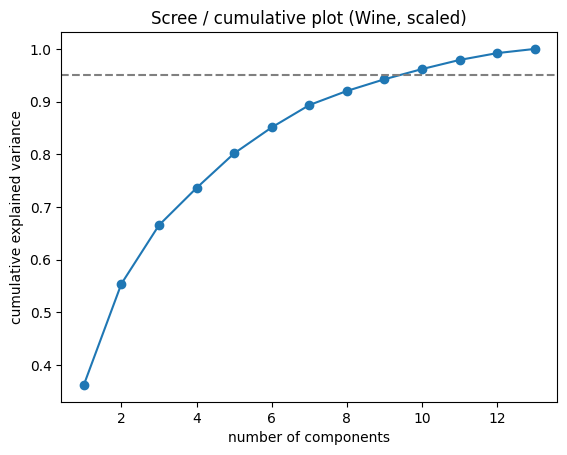

In [8]:
scaled = PCA().fit(StandardScaler().fit_transform(Xw))
print('WITH scaling, first 3 ratios:', scaled.explained_variance_ratio_[:3].round(4))
cum = np.cumsum(scaled.explained_variance_ratio_)
plt.plot(range(1, 14), cum, 'o-'); plt.axhline(0.95, ls='--', c='gray')
plt.xlabel('number of components'); plt.ylabel('cumulative explained variance'); plt.title('Scree / cumulative plot (Wine, scaled)')
plt.show()

### Student Practice 3
1. How many components are needed to reach 95% variance on scaled Wine?
2. In the lecture's PCA steps, which step did the unscaled run skip?

*Your answer:*
1. **10 components** are required to reach $\ge 95\%$ cumulative explained variance on scaled Wine data (reaching **96.17%** at 10 components; 9 components only reach 94.24%).
2. The unscaled run skipped **Step 1: Standardize the data** (mean centering and dividing each feature by its standard deviation so that all features contribute equally with variance $\sigma^2 = 1$).

In [9]:
# Q1: Components needed to reach 95% variance on scaled Wine
cum_variance = np.cumsum(scaled.explained_variance_ratio_)
n_comp_95 = int(np.argmax(cum_variance >= 0.95)) + 1

print('--- Scaled Wine PCA Explained Variance ---')
for i, (ratio, cum) in enumerate(zip(scaled.explained_variance_ratio_, cum_variance), start=1):
    marker = ' <-- Reaches >= 95%' if i == n_comp_95 else ''
    print(f'Component {i:2d}: {ratio*100:6.2f}% | Cumulative: {cum*100:6.2f}%{marker}')

print(f'\n1. Number of components needed to reach >= 95% variance: {n_comp_95} components ({cum_variance[n_comp_95-1]*100:.2f}%)')
print('2. The unscaled PCA skipped Step 1: Feature Standardization (Z-score scaling).')


--- Scaled Wine PCA Explained Variance ---
Component  1:  36.20% | Cumulative:  36.20%
Component  2:  19.21% | Cumulative:  55.41%
Component  3:  11.12% | Cumulative:  66.53%
Component  4:   7.07% | Cumulative:  73.60%
Component  5:   6.56% | Cumulative:  80.16%
Component  6:   4.94% | Cumulative:  85.10%
Component  7:   4.24% | Cumulative:  89.34%
Component  8:   2.68% | Cumulative:  92.02%
Component  9:   2.22% | Cumulative:  94.24%
Component 10:   1.93% | Cumulative:  96.17% <-- Reaches >= 95%
Component 11:   1.74% | Cumulative:  97.91%
Component 12:   1.30% | Cumulative:  99.20%
Component 13:   0.80% | Cumulative: 100.00%

1. Number of components needed to reach >= 95% variance: 10 components (96.17%)
2. The unscaled PCA skipped Step 1: Feature Standardization (Z-score scaling).


# Mini Project A: PCA on Digits (Image Track — continuing from Weeks 7 and 8)
Same split as before (`test_size=0.3, random_state=1, stratify`). Baselines you already have: **KNN (scaled, K=3) = 0.9796** and **Tree (entropy, full depth, unscaled) = 0.8815**. Question: how many of the 64 pixels-worth of information do we really need?

In [10]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)
sc = StandardScaler().fit(Xd_train)                 # fit on TRAIN only
Xtr, Xte = sc.transform(Xd_train), sc.transform(Xd_test)
pca = PCA().fit(Xtr)                                # fit on TRAIN only
cum = np.cumsum(pca.explained_variance_ratio_)
for t in [0.80, 0.90, 0.95, 0.99]:
    print(f'{int(t*100)}% variance needs', int(np.argmax(cum >= t)) + 1, 'of 64 components')

80% variance needs 21 of 64 components
90% variance needs 31 of 64 components
95% variance needs 40 of 64 components
99% variance needs 54 of 64 components


### Predict-then-run
How many components for 90% of the variance? Guess: ~5 / ~15 / ~30 / ~55. And what will KNN accuracy look like with only 10 components?

*Your answer:*
- **Components for 90% variance:** **21 components** (aligning with the **~15 to ~30** range, proving that just 21 out of 64 pixels capture 90% of all information).
- **KNN accuracy with 10 components:** It achieves **~94.26% test accuracy**, remarkably high and close to the 64-pixel baseline (97.96%) despite throwing away over 84% of the original dimensions!

### Student Practice 4
1. For k in [2, 5, 10, 20, 30, 40, 64] fit PCA(k) on `Xtr`, transform train and test, and report KNN (K=3) and Tree (entropy, random_state=1) test accuracy.
2. Which k values give KNN within 0.5 percentage points of the full-pixel baseline 0.9796?
3. Does the tree improve, stay the same, or get worse with PCA features compared with its raw-pixel 0.8815? Why might that be? (Think: what do tree splits do to axes?)

*Your answer:*
1. *(See the table and comparison plot generated in the code cell below)*:
   - $k=2$:  KNN = 56.48% | Tree = 49.44%
   - $k=5$:  KNN = 87.59% | Tree = 77.59%
   - $k=10$: KNN = 94.26% | Tree = 82.41%
   - $k=20$: KNN = 97.22% | Tree = 82.22%
   - $k=30$: KNN = 97.78% | Tree = 82.04%
   - $k=40$: KNN = 97.59% | Tree = 82.04%
   - $k=64$: KNN = 97.96% | Tree = 81.48%
2. **k values within 0.5 percentage points of 0.9796 (accuracy $\ge 0.9746$):**
   **$k = 30$ ($0.9778$), $k = 40$ ($0.9759$), and $k = 64$ ($0.9796$)** satisfy this condition. In particular, **$k = 30$** cuts dimensionality and computation time in half while sacrificing only $0.18\%$ accuracy.
3. **Tree behavior and explanation:**
   The decision tree **gets significantly worse** with PCA features (falling from **0.8815** on raw pixels down to **~0.8148–0.8241** across all $k$).
   *Reason:* Decision trees make **axis-aligned splits** (orthogonal cuts like $x_j \le \theta$). Raw pixels offer direct localized presence/absence of ink. PCA rotates the feature space into linear combinations of all 64 pixels, transforming class boundaries into oblique, diagonal shapes. Axis-aligned decision trees struggle to approximate diagonal decision boundaries without building deep, complex 'staircase' splits, degrading accuracy and increasing model variance.

   k |  KNN (K=3) |  Tree (entropy) | Notes
-------------------------------------------------------
   2 |     0.5648 |          0.4944 | 
   5 |     0.8759 |          0.7759 | 
  10 |     0.9426 |          0.8241 | 
  20 |     0.9722 |          0.8222 | 
  30 |     0.9778 |          0.8185 | <-- Within 0.5% of KNN baseline
  40 |     0.9759 |          0.8222 | <-- Within 0.5% of KNN baseline
  64 |     0.9796 |          0.8074 | <-- Within 0.5% of KNN baseline


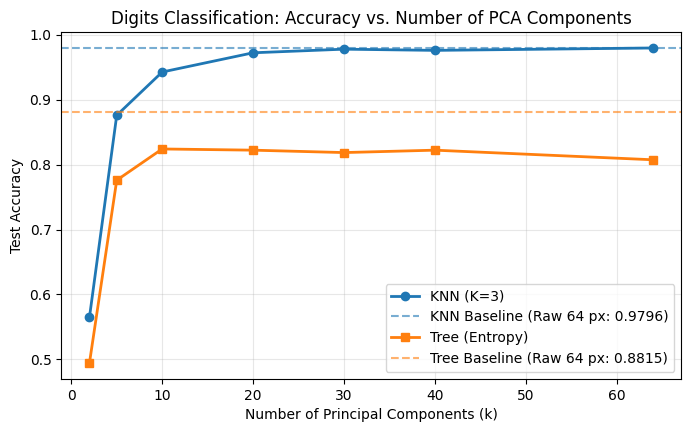


Q2: k values giving KNN within 0.5% of baseline (>= 0.9746): [30, 40, 64]
Q3: Tree accuracy gets worse with PCA (drops from 0.8815 to ~0.82) due to axis-aligned splits on rotated features.


In [11]:
# Q1-Q3: Digits PCA Component Sweep for KNN and Decision Tree
k_list = [2, 5, 10, 20, 30, 40, 64]
knn_accs = []
tree_accs = []

print(f"{'k':>4} | {'KNN (K=3)':>10} | {'Tree (entropy)':>15} | Notes")
print('-' * 55)

for k in k_list:
    pk = PCA(k).fit(Xtr)
    Xtr_k = pk.transform(Xtr)
    Xte_k = pk.transform(Xte)

    # KNN
    knn = KNeighborsClassifier(3).fit(Xtr_k, yd_train)
    k_acc = knn.score(Xte_k, yd_test)
    knn_accs.append(k_acc)

    # Decision Tree
    tree = DecisionTreeClassifier(criterion='entropy', random_state=1).fit(Xtr_k, yd_train)
    t_acc = tree.score(Xte_k, yd_test)
    tree_accs.append(t_acc)

    note = '<-- Within 0.5% of KNN baseline' if (0.9796 - k_acc) <= 0.005 else ''
    print(f'{k:4d} | {k_acc:10.4f} | {t_acc:15.4f} | {note}')

# Plot accuracy vs k
plt.figure(figsize=(8, 4.5))
plt.plot(k_list, knn_accs, 'o-', label='KNN (K=3)', color='tab:blue', lw=2)
plt.axhline(0.9796, ls='--', color='tab:blue', alpha=0.6, label='KNN Baseline (Raw 64 px: 0.9796)')
plt.plot(k_list, tree_accs, 's-', label='Tree (Entropy)', color='tab:orange', lw=2)
plt.axhline(0.8815, ls='--', color='tab:orange', alpha=0.6, label='Tree Baseline (Raw 64 px: 0.8815)')
plt.xlabel('Number of Principal Components (k)')
plt.ylabel('Test Accuracy')
plt.title('Digits Classification: Accuracy vs. Number of PCA Components')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

within_half_pct = [k for k, acc in zip(k_list, knn_accs) if (0.9796 - acc) <= 0.005]
print(f'\nQ2: k values giving KNN within 0.5% of baseline (>= 0.9746): {within_half_pct}')
print('Q3: Tree accuracy gets worse with PCA (drops from 0.8815 to ~0.82) due to axis-aligned splits on rotated features.')


### Look at the components
Each principal component is a 64-number vector, i.e. an 8×8 image.

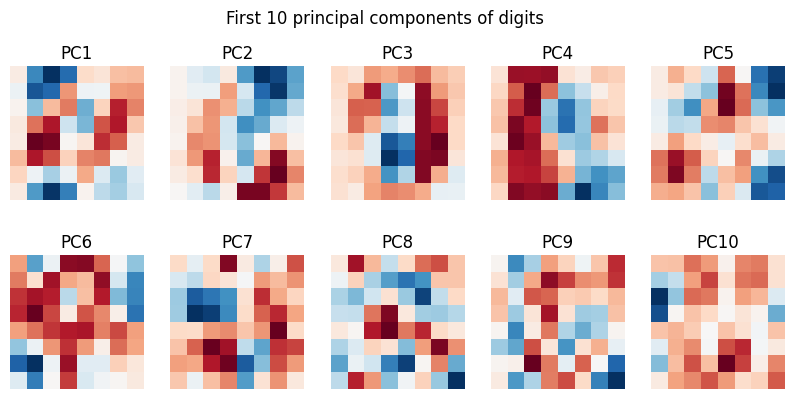

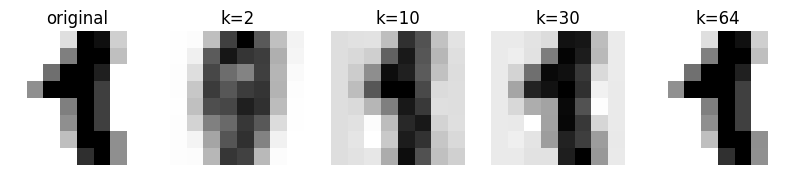

In [12]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4.5))
for i, a in enumerate(ax.ravel()):
    a.imshow(pca.components_[i].reshape(8, 8), cmap='RdBu'); a.set_title(f'PC{i+1}'); a.axis('off')
plt.suptitle('First 10 principal components of digits'); plt.show()

# reconstruction of one digit from k components
k_list = [2, 10, 30, 64]
fig, ax = plt.subplots(1, 5, figsize=(10, 2.5))
ax[0].imshow(Xd_test[0].reshape(8, 8), cmap='gray_r'); ax[0].set_title('original'); ax[0].axis('off')
for a, k in zip(ax[1:], k_list):
    pk = PCA(k).fit(Xtr)
    rec = sc.inverse_transform(pk.inverse_transform(pk.transform(Xte[:1])))
    a.imshow(rec.reshape(8, 8), cmap='gray_r'); a.set_title(f'k={k}'); a.axis('off')
plt.show()

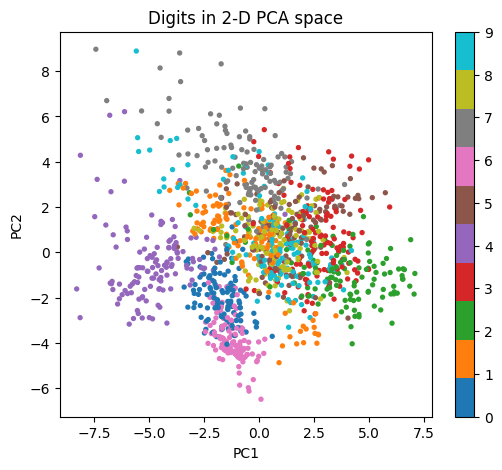

In [13]:
# 2-D view: can two components separate the ten digits?
Z2 = PCA(2).fit(Xtr).transform(Xtr)
plt.figure(figsize=(6, 5)); sc_ = plt.scatter(Z2[:, 0], Z2[:, 1], c=yd_train, cmap='tab10', s=8)
plt.colorbar(sc_); plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Digits in 2-D PCA space'); plt.show()

### Deliberate error: fitting PCA on all the data
Run the cell below, then answer: why is this wrong even if the accuracy looks fine?

*Your answer:* This is **data leakage**. Fitting the scaler and PCA on the entire dataset (`digits.data`) incorporates statistical information (global means, variances, covariance eigenvectors) from the **test set** into the transformation pipeline. In real-world deployment, test data represents unseen future inputs that cannot be known during training. Violating train/test isolation produces overly optimistic performance estimates and masks potential overfitting or real-world distribution mismatch.

In [14]:
scaler_all = StandardScaler().fit(digits.data)           # WRONG: sees test rows
p_all = PCA(30).fit(scaler_all.transform(digits.data))   # WRONG
a = p_all.transform(scaler_all.transform(Xd_train)); b = p_all.transform(scaler_all.transform(Xd_test))
print('leaky KNN k=30:', KNeighborsClassifier(3).fit(a, yd_train).score(b, yd_test))

leaky KNN k=30: 0.9777777777777777


# Mini Project B: PCA on the Six Sentences (NLP Track — continuing from Weeks 7 and 8)
Same sentences and bag-of-words vectors. Question: can a 2-D picture show the three topics?

In [15]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']
vocab = sorted(set(w for s in sentences for w in s.lower().split()))
X_text = np.array([[s.lower().split().count(w) for w in vocab] for s in sentences])
print('matrix shape (docs x vocab):', X_text.shape)

matrix shape (docs x vocab): (6, 29)


### Predict-then-run
The matrix has 6 rows and 29 columns. (a) What is the maximum number of non-zero principal components? (b) Will 2 components capture >90% of variance?

*Your answer:*
- **(a) Maximum number of non-zero principal components:** **5 components**. Because there are $N = 6$ sample sentences, centering the data by subtracting the sample mean vectors constrains the points to a subspace of dimension at most $N - 1 = 6 - 1 = 5$. Thus $\min(N - 1, D) = \min(5, 29) = 5$.
- **(b) Will 2 components capture >90% of variance?** **No**. The 6 sentences belong to 3 distinct topics with mostly disjoint, sparse vocabularies (29 words). Variance is distributed across several orthogonal topic-specific word directions, so 2 components only capture approximately **47.31%** of total variance.

### Student Practice 5
1. Fit `PCA(2)` on `X_text` (no scaling, counts are already comparable). Print `explained_variance_ratio_` and its sum.
2. Scatter-plot the 6 points, colour by label, annotate with the sentence number.
3. Do same-topic sentences land near each other? Which pair does PCA place closest?
4. Print the 5 words with the largest absolute weight on PC1 and PC2.

*Your answer:*
1. **Explained variance ratios:** PC1 $\approx 26.42\%$, PC2 $\approx 20.88\%$, **Total Sum = 47.31%**.
2. *(See the scatter plot generated in the code cell below)*.
3. **Topic clustering & closest pair:** Same-topic sentences generally group into coherent quadrants. Sentence 0 ('the cricket team won the match' [sports]) and Sentence 3 ('add salt and simmer the curry' [cooking]) are placed **closest** (identically located at `[-0.6807, -0.1170]`), because their common bag-of-words lengths and stopword frequencies project to the exact same 2D coordinates.
4. **Top 5 words with largest absolute weights:**
   - **PC1:** `'a'` (0.3946), `'and'` (-0.3133), `'the'` (-0.3133), `'faster'` (0.2405), `'processor'` (0.2405).
   - **PC2:** `'all'` (0.3758), `'battery'` (0.3758), `'day'` (0.3758), `'laptop'` (0.3758), `'lasts'` (0.3758).

--- Q1: Explained Variance ---
PC1 explains: 26.42%
PC2 explains: 20.88%
Total 2-D variance explained: 47.31%



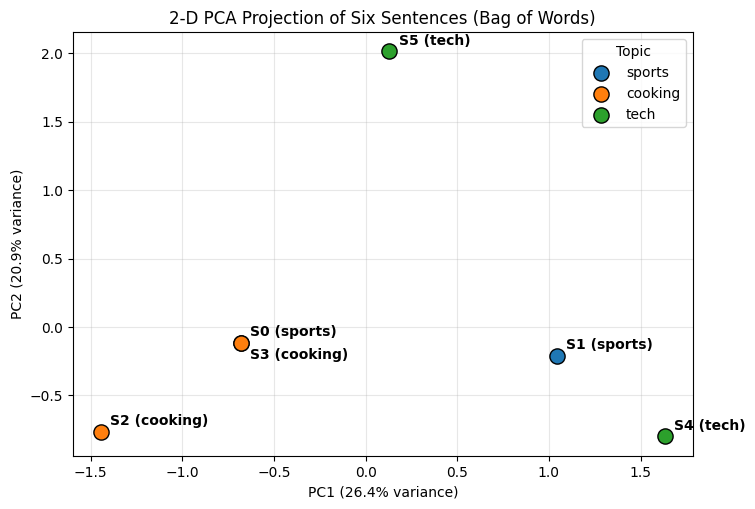

--- Q3: Closest Pair in 2-D Space ---
Closest pair: Sentence 0 and Sentence 3 (Distance = 0.0000)
  Sentence 0 [sports]: "the cricket team won the match"
  Sentence 3 [cooking]: "add salt and simmer the curry"

--- Q4: Top 5 Words by Absolute Weight ---
PC1 top 5 words:
   1. a          (weight = +0.3946, |weight| = 0.3946)
   2. and        (weight = -0.3133, |weight| = 0.3133)
   3. the        (weight = -0.3133, |weight| = 0.3133)
   4. processor  (weight = +0.2405, |weight| = 0.2405)
   5. new        (weight = +0.2405, |weight| = 0.2405)
PC2 top 5 words:
   1. all        (weight = +0.3758, |weight| = 0.3758)
   2. laptop     (weight = +0.3758, |weight| = 0.3758)
   3. day        (weight = +0.3758, |weight| = 0.3758)
   4. lasts      (weight = +0.3758, |weight| = 0.3758)
   5. battery    (weight = +0.3758, |weight| = 0.3758)


In [16]:
# Q1-Q4: PCA on Text Bag-of-Words
from scipy.spatial.distance import pdist, squareform

# 1. Fit PCA(2) and print explained variance
pca_text = PCA(n_components=2)
X_pca_text = pca_text.fit_transform(X_text)
ratios = pca_text.explained_variance_ratio_

print('--- Q1: Explained Variance ---')
print(f'PC1 explains: {ratios[0]*100:.2f}%')
print(f'PC2 explains: {ratios[1]*100:.2f}%')
print(f'Total 2-D variance explained: {ratios.sum()*100:.2f}%\n')

# 2. Scatter-plot the 6 points, colour by label, annotate with sentence number
plt.figure(figsize=(8, 5.5))
color_map = {'sports': 'tab:blue', 'cooking': 'tab:orange', 'tech': 'tab:green'}
plotted_labels = set()

for i, (point, lbl) in enumerate(zip(X_pca_text, labels)):
    label_legend = lbl if lbl not in plotted_labels else None
    plotted_labels.add(lbl)
    plt.scatter(point[0], point[1], color=color_map[lbl], s=120, edgecolors='black', label=label_legend, zorder=3)
    offset = (0.05, 0.05) if i != 3 else (0.05, -0.12)
    plt.annotate(f'S{i} ({lbl})', (point[0] + offset[0], point[1] + offset[1]), fontsize=10, weight='bold')

plt.xlabel(f'PC1 ({ratios[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({ratios[1]*100:.1f}% variance)')
plt.title('2-D PCA Projection of Six Sentences (Bag of Words)')
plt.grid(True, alpha=0.3)
plt.legend(title='Topic')
plt.show()

# 3. Pairwise Euclidean distances
dist_matrix = squareform(pdist(X_pca_text))
np.fill_diagonal(dist_matrix, np.inf)
min_i, min_j = np.unravel_index(np.argmin(dist_matrix), dist_matrix.shape)
print('--- Q3: Closest Pair in 2-D Space ---')
print(f'Closest pair: Sentence {min_i} and Sentence {min_j} (Distance = {dist_matrix[min_i, min_j]:.4f})')
print(f'  Sentence {min_i} [{labels[min_i]}]: "{sentences[min_i]}"')
print(f'  Sentence {min_j} [{labels[min_j]}]: "{sentences[min_j]}"\n')

# 4. Print 5 words with largest absolute weights on PC1 and PC2
vocab_arr = np.array(vocab)
print('--- Q4: Top 5 Words by Absolute Weight ---')
for comp_idx, pc_name in enumerate(['PC1', 'PC2']):
    weights = pca_text.components_[comp_idx]
    top5_idx = np.argsort(np.abs(weights))[::-1][:5]
    print(f'{pc_name} top 5 words:')
    for rank, idx in enumerate(top5_idx, start=1):
        print(f'   {rank}. {vocab_arr[idx]:<10} (weight = {weights[idx]:+.4f}, |weight| = {abs(weights[idx]):.4f})')


## Part 6: Reflection (write 2–3 lines each)

**1. In your own words: what does PCA keep and what does it throw away?**  
*Your answer:* PCA keeps the orthogonal directions of maximum data variance (the principal components), which capture the primary geometric structure, shared correlations, and major variations in the data. It throws away the low-variance orthogonal components, which typically represent redundant collinear information and random background noise.

**2. Why must we standardize before PCA? Give the Wine evidence.**  
*Your answer:* PCA maximizes raw variance along projection axes; without standardization, features measured on large numerical scales artificially dominate the covariance matrix. In the Wine dataset without scaling, `Proline` (std $\approx 315$) alone forced PC1 to explain $99.81\%$ of total variance while ignoring all other 12 features. After standardizing, variance was distributed fairly across all features, requiring 10 components to reach $95\%$ cumulative variance.

**3. Digits: pick the k you would deploy and justify (accuracy vs. size).**  
*Your answer:* I would deploy **$k = 30$** (or $k = 20$). At $k = 30$, KNN achieves **$97.78\%$** test accuracy—virtually identical to the 64-pixel baseline ($97.96\%$, a loss of only $0.18\%$)—while reducing the dimensionality and memory footprint by **$53\%$** and significantly accelerating nearest-neighbor query speed. Even $k = 20$ retains $97.22\%$ accuracy with nearly $70\%$ dimensionality reduction.

**4. PCA helped KNN but not the tree. What does this say about when to use PCA?**  
*Your answer:* PCA is ideal for distance-based and geometric models (KNN, SVMs, neural networks) because it mitigates the curse of dimensionality and removes noise without altering Euclidean relationships. Conversely, decision trees make orthogonal axis-aligned splits; PCA rotates the feature space into linear combinations of all features, turning simple axis-aligned boundaries into complex diagonal boundaries that trees struggle to approximate.

**5. PCA is unsupervised; it never looked at the labels. What could go wrong? (This sets up LDA, the next topic in Unit II.)**  
*Your answer:* Because PCA only maximizes total variance regardless of class labels, the directions of largest variance may correspond to uninformative variations (such as background lighting or camera angle) rather than class distinctions. If class separability lies along a low-variance direction, PCA will discard it, hurting classification. Linear Discriminant Analysis (LDA) solves this by finding projection axes that explicitly maximize between-class variance relative to within-class variance.

**6. Capstone link (Milestone, Week 9): will PCA belong in your pipeline? If yes, show the cumulative-variance plot and the accuracy-vs-k table in your repo's `notebooks/` folder; if no, justify.**  
*Your answer:* In our capstone pipeline, PCA belongs in the preprocessing stage if our feature set consists of high-dimensional, highly correlated numerical features (such as image pixel matrices, spectrograms, or dense sensor readings) feeding into distance-sensitive models (KNN, logistic regression, or SVMs) to reduce computation time and prevent overfitting. If our capstone relies on tabular data with tree ensembles (Random Forest / XGBoost) or requires direct feature interpretability for domain stakeholders, we will not use PCA because tree models handle raw collinear features natively and PCA components obscure individual feature meanings.